In [1]:
#Get the imports
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from astropy.io import ascii
import astropy.units as u
import astropy.constants as const
from astropy.modeling.powerlaws import BrokenPowerLaw1D, SmoothlyBrokenPowerLaw1D, PowerLaw1D
from astropy.modeling import fitting, models

In [2]:
#The Radio data
#February 6, 2014 = t_0

V745_radio = pd.read_csv('2014_Sco.dat', delim_whitespace = True, header = 0)

freq = V745_radio['Freq']
flux = V745_radio['Flux']
err = V745_radio['eFlux']
mjd = V745_radio['MJD']



/var/folders/xv/dvsld6lx4xs_nbgh_qcl11d00000gn/T/ipykernel_17255/4191143678.py:4: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  V745_radio = pd.read_csv('2014_Sco.dat', delim_whitespace = True, header = 0)


In [3]:
#mjd to date 
#mjd t_0 = 56694

def MJD_to_date(MJD, first):
    days = []
    for i in range(len(MJD)):
        days.append(float(MJD[i]) - first)
    return(days)

day = np.array(MJD_to_date(mjd,56694))

In [4]:
#Sort data by freq and non detections 

A = np.logical_and(freq>= 0, freq<= 1.5) 
L_AC = np.where(np.logical_and(A, flux > 3*err)) 
L_nac = np.where(np.logical_and(A, flux < 3*err))

freq_LAC = np.ravel([freq[i] for i in L_AC])
flux_LAC = np.ravel([flux[i] for i in L_AC])
err_LAC  = np.ravel([err[i] for i in L_AC])
date_LAC = np.ravel([day[i] for i in L_AC])

nflux_LAC = np.ravel([flux[i] + err[i]*3 for i in L_nac])
ndate_LAC = np.ravel([day[i] for i in L_nac])


###############################################################
B = np.logical_and(freq>= 1.5, freq<= 2)
L_BD = np.where(np.logical_and(B, flux > 3*err)) 
L_nbd = np.where(np.logical_and(B, flux < 3*err))

freq_LBD = np.ravel([freq[i] for i in L_BD])
flux_LBD = np.ravel([flux[i] for i in L_BD])
err_LBD  = np.ravel([err[i] for i in L_BD])
date_LBD = np.ravel([day[i] for i in L_BD])

nflux_LBD = np.ravel([flux[i] + err[i]*3 for i in L_nbd])
ndate_LBD = np.ravel([day[i] for i in L_nbd])


###############################################################
C = np.logical_and(freq>= 3, freq<= 5)
C_AC = np.where(np.logical_and(C, flux > 3*err)) 
C_nac = np.where(np.logical_and(C, flux < 3*err))

freq_CAC = np.ravel([freq[i] for i in C_AC])
flux_CAC = np.ravel([flux[i] for i in C_AC])
err_CAC  = np.ravel([err[i] for i in C_AC])
date_CAC = np.ravel([day[i] for i in C_AC])

nflux_CAC = np.ravel([flux[i] + err[i]*3 for i in C_nac])
ndate_CAC = np.ravel([day[i] for i in C_nac])


###############################################################
D = np.logical_and(freq>= 6, freq<= 8) 
C_BD = np.where(np.logical_and(D, flux > 3*err)) 
C_nbd = np.where(np.logical_and(D, flux < 3*err))

freq_CBD = np.ravel([freq[i] for i in C_BD])
flux_CBD = np.ravel([flux[i] for i in C_BD])
err_CBD  = np.ravel([err[i] for i in C_BD])
date_CBD = np.ravel([day[i] for i in C_BD])

nflux_CBD = np.ravel([flux[i] + err[i]*3 for i in C_nbd])
ndate_CBD = np.ravel([day[i] for i in C_nbd])

###############################################################
E = np.logical_and(freq>= 10, freq<= 14)
Ku_AC =  np.where(np.logical_and(E, flux > 3*err))  
Ku_nac = np.where(np.logical_and(E, flux < 3*err))  

freq_K_AC = np.ravel([freq[i] for i in Ku_AC])
flux_K_AC = np.ravel([flux[i] for i in Ku_AC])
err_K_AC  = np.ravel([err[i] for i in Ku_AC])
date_K_AC = np.ravel([day[i] for i in Ku_AC])

nflux_K_AC = np.ravel([flux[i] + err[i]*3 for i in Ku_nac])
ndate_K_AC = np.ravel([day[i] for i in Ku_nac])
###############################################################
F = np.logical_and(freq>= 16, freq<= 20)
Ku_BD =  np.where(np.logical_and(F, flux > 3*err))  
Ku_nbd = np.where(np.logical_and(F, flux < 3*err))  

freq_K_BD = np.ravel([freq[i] for i in Ku_BD])
flux_K_BD = np.ravel([flux[i] for i in Ku_BD])
err_K_BD  = np.ravel([err[i] for i in Ku_BD])
date_K_BD = np.ravel([day[i] for i in Ku_BD])

nflux_K_BD = np.ravel([flux[i] + err[i]*3 for i in Ku_nbd])
ndate_K_BD = np.ravel([day[i] for i in Ku_nbd])
###############################################################

G = np.logical_and(freq>= 21, freq<= 30)
Ka_AC =  np.where(np.logical_and(G, flux > 3*err)) 
Ka_nac = np.where(np.logical_and(G, flux < 3*err)) 

freq_Ka_AC = np.ravel([freq[i] for i in Ka_AC])
flux_Ka_AC = np.ravel([flux[i] for i in Ka_AC])
err_Ka_AC  = np.ravel([err[i] for i in Ka_AC])
date_Ka_AC = np.ravel([day[i] for i in Ka_AC])

nflux_Ka_AC = np.ravel([flux[i] + err[i]*3 for i in Ka_nac])
ndate_Ka_AC = np.ravel([day[i] for i in Ka_nac])
###############################################################

H = np.logical_and(freq>= 31, freq<= 40)
Ka_BD =  np.where(np.logical_and(H, flux > 3*err))  
Ka_nbd = np.where(np.logical_and(H, flux < 3*err))

freq_Ka_BD = np.ravel([freq[i] for i in Ka_BD])
flux_Ka_BD = np.ravel([flux[i] for i in Ka_BD])
err_Ka_BD  = np.ravel([err[i] for i in Ka_BD])
date_Ka_BD = np.ravel([day[i] for i in Ka_BD])

nflux_Ka_BD = np.ravel([flux[i] + err[i]*3 for i in Ka_nbd])
ndate_Ka_BD = np.ravel([day[i] for i in Ka_nbd])

In [5]:
def quad(err,freq,flux):
    quad_er = []

    for i in range(len(freq)):
        if freq[i] < 10.0:
            p1 = np.sqrt(err[i]**2 + (flux[i]*0.05)**2)
            quad_er.append(p1)
        
        else: 
            p2 = np.sqrt(err[i]**2 + (flux[i]*0.10)**2)
            quad_er.append(p2)
            
        
    return(quad_er)  

In [6]:
#Error in Quadrature

quad_Lac = quad(err_LAC,freq_LAC, flux_LAC)  
quad_Lbd = quad(err_LBD,freq_LBD, flux_LBD)   
quad_Cac = quad(err_CAC,freq_CAC, flux_CAC)
quad_Cbd = quad(err_CBD,freq_CBD, flux_CBD)
quad_Kac = quad(err_K_AC,freq_K_AC, flux_K_AC)
quad_Kbd = quad(err_K_BD,freq_K_BD, flux_K_BD)
quad_Kaac = quad(err_Ka_AC,freq_Ka_AC, flux_Ka_AC)
quad_Kabd = quad(err_Ka_BD,freq_Ka_BD, flux_Ka_BD)


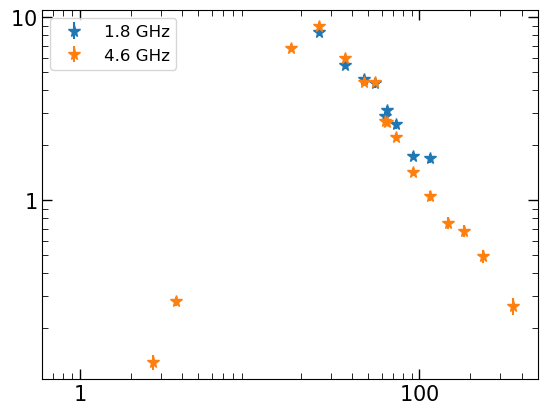

In [7]:

plt.xscale('log')
plt.yscale('log')


plt.errorbar(date_LBD, flux_LBD, yerr=quad_Lbd, fmt = '*' , markersize = 8.5, label='1.8 GHz')
plt.errorbar(date_CAC, flux_CAC, yerr=quad_Cac,  fmt = '*', markersize = 8.5, label='4.6 GHz')

plt.yticks([1.0,10], labels = [r'$1$',r'$10$'], fontsize = 15)
plt.xticks([1,100], labels = [r'$1$',r'$100$'], fontsize = 15)
plt.xlim([0.6,500])
plt.tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
plt.tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

plt.legend(fontsize=12, loc='upper left')


# Now for the optical data 

In [8]:
#optical data input
#JD: 2456694.5000000

V745Sco_opt_unflitered = pd.read_csv('V745Sco_optical.txt', header = 0)

#now to get only the vband

column_name = 'Band'
key = 'V'

V745Sco_opt_kinda = V745Sco_opt_unflitered[V745Sco_opt_unflitered[column_name].str.contains(key, na=False)]

V745Sco_opt = V745Sco_opt_kinda[~V745Sco_opt_kinda[column_name].str.contains('Vis.|CV', na=False)]

V745Sco_opt

,JD,Magnitude,Uncertainty,HQuncertainty,Band,Observer Code,Comment Code(s),Comp Star 1,Comp Star 2,Charts,...,Cmag,Kmag,HJD,Star Name,Observer Affiliation,Measurement Method,Grouping Method,ADS Reference,Digitizer,Credit
10,2.456695e+06,8.66,0.0600,NaN,V,OCN,NaN,91,111,13202ECB,...,9.1360,11.0840,NaN,V745 SCO,AAVSO,STD,NaN,NaN,NaN,NaN
14,2.456696e+06,10.0322,0.0027,NaN,V,SFU,NaN,000-BJM-534,000-BJM-459,13208ABV,...,11.6340,14.1379,NaN,V0745 SCO,VSS,STD,NaN,NaN,NaN,NaN
15,2.456696e+06,10.0712,0.0011,NaN,V,SFU,NaN,000-BJM-534,000-BJM-459,13208ABV,...,10.4990,12.9851,NaN,V0745 SCO,VSS,STD,NaN,NaN,NaN,NaN
16,2.456696e+06,10.0727,0.0011,NaN,V,SFU,NaN,000-BJM-534,000-BJM-459,13208ABV,...,10.4773,12.9349,NaN,V0745 SCO,VSS,STD,NaN,NaN,NaN,NaN
17,2.456696e+06,10.0706,0.0010,NaN,V,SFU,NaN,000-BJM-534,000-BJM-459,13208ABV,...,10.4421,12.9138,NaN,V0745 SCO,VSS,STD,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2219,2.456730e+06,16.949,0.2700,NaN,V,HMB,NaN,000-BKM-464,000-BKM-460,13202EBS,...,18.7810,17.0010,NaN,V0745 SCO,VVS,STD,NaN,NaN,NaN,NaN
2221,2.456730e+06,16.816,0.2490,NaN,V,HMB,NaN,000-BKM-464,000-BKM-460,13202EBS,...,18.8200,17.0600,NaN,V0745 SCO,VVS,STD,NaN,NaN,NaN,NaN
2223,2.456730e+06,16.776,0.2310,NaN,V,HMB,NaN,000-BKM-464,000-BKM-460,13202EBS,...,18.7090,16.9360,NaN,V0745 SCO,VVS,STD,NaN,NaN,NaN,NaN
2529,2.456737e+06,17.10,0.1500,NaN,V,OCN,NaN,144,152,13300CUW,...,14.4150,15.1540,NaN,V745 SCO,AAVSO,STD,NaN,NaN,NaN,NaN


In [9]:
#Feb. 6 2014
#JD t_0 = 2456694.5000000

opticaldays = ((V745Sco_opt['JD'].astype(float)) - 2456694.5000000)
vmag = V745Sco_opt['Magnitude'].astype(float)
error_vmag = V745Sco_opt['Uncertainty'].astype(float)

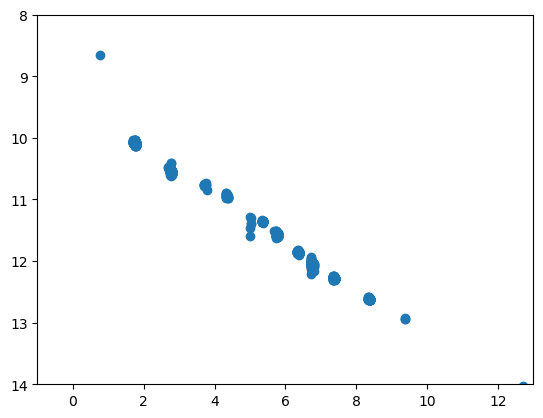

In [10]:
plt.scatter(opticaldays, vmag)
plt.xlim(-1,13)
plt.ylim(8,14)
plt.gca().invert_yaxis()

plt.show()

In [11]:
#Spectral Index over Time

alpha_1 = [0.73, 0.07, 0.17, 0.02, 0.03, 0.25, -0.17, -0.17]
alpha_e1 = [0.17, 0.06, 0.04, 0.04, 0.04, 0.02, 0.01, 0.02]

alph = [1.27, -0.23, -0.24, 0.19,0.03,0.06]
alph_e = [0.23, 0.09,0.24,0.09,0.11,0.29]


alpha_2 = [1.21, -2.10, -0.24, -0.57, -0.13, -0.13, 0.15, 0.13]
alpha_e2 = [ 0.56, 0.91, 0.04, 0.34, 0.08, 0.02, 0.06, 0.17]

DaySIO = [3.4, 17.5, 25.5, 38.5, 47.5, 54.4, 64.5, 73.4]
dalph = [2,92.3,115.3,148.5,182,244]


In [15]:
flux_Ka_BD

array([2.5  , 5.4  , 5.08 , 3.03 , 3.22 , 3.77 , 2.9  , 2.86 , 2.14 ,
       0.585, 0.932, 1.   , 0.324])

In [16]:
date_Ka_BD

array([  3.7 ,  17.5 ,  25.6 ,  36.5 ,  47.5 ,  54.5 ,  62.4 ,  64.5 ,
        73.4 ,  92.3 , 115.3 , 148.5 , 243.97])

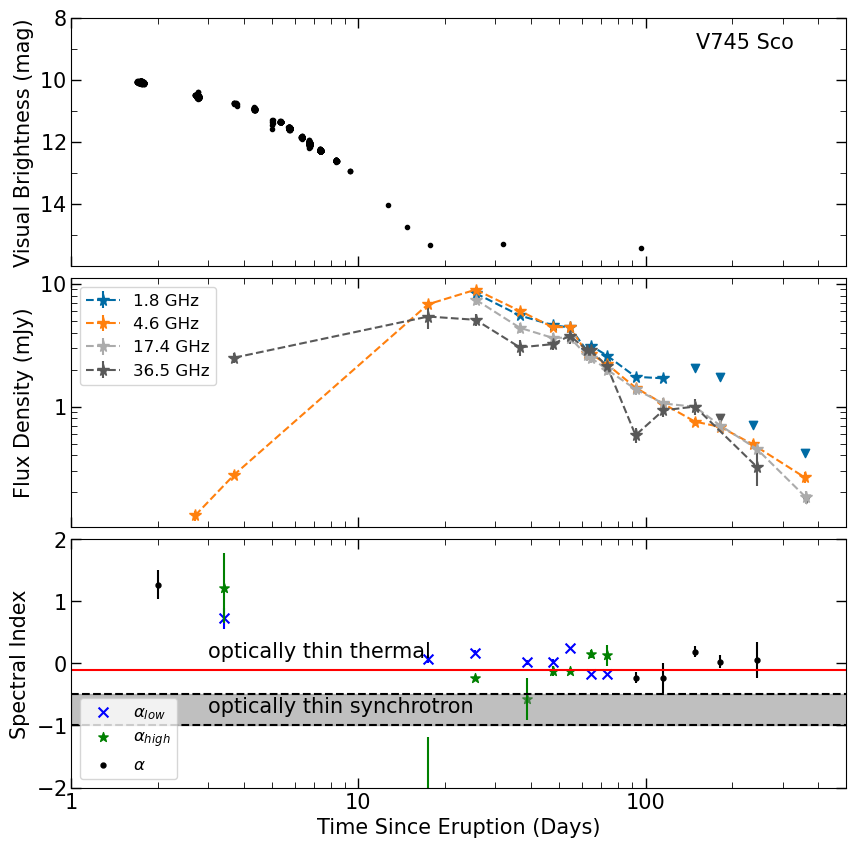

In [12]:
plt.style.use('tableau-colorblind10')

from matplotlib.ticker import AutoMinorLocator

fig, axs = plt.subplots(3, 1, figsize=(10, 10), sharey=False, sharex = True)

########## Panel 1 #############
axs[0].scatter(opticaldays, vmag, marker = '.', color = 'black')
axs[0].annotate('V745 Sco',(150,9), fontsize=15)

axs[0].set_xscale('log')

axs[0].set_yticks([8,10,12,14], labels = [r'$8$',r'$10$', r'$12$', r'$14$'], fontsize = 15)
axs[0].set_ylim(8,16)
axs[0].invert_yaxis()
axs[0].tick_params(which='minor', length=4, direction = 'in', top=True, labeltop=False, left=True, labelleft=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[0].yaxis.set_minor_locator(AutoMinorLocator(2))  # 2 minor intervals between major ticks
axs[0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)

axs[0].set_ylabel('Visual Brightness (mag)',fontsize =15)

########## Panel 2 #############
axs[1].set_xscale('log')
axs[1].set_yscale('log')


axs[1].errorbar(date_LBD, flux_LBD, yerr=quad_Lbd, linestyle ='--', fmt = '*' , markersize = 8.5, label='1.8 GHz')
axs[1].errorbar(date_CAC, flux_CAC, yerr=quad_Cac, linestyle ='--', fmt = '*', markersize = 8.5, label='4.6 GHz')
axs[1].errorbar(date_K_BD, flux_K_BD, yerr=quad_Kbd, linestyle ='--', fmt = '*', markersize = 8.5 , label='17.4 GHz')
axs[1].errorbar(date_Ka_BD, flux_Ka_BD, yerr=quad_Kabd, linestyle ='--', fmt = '*' , markersize = 8.5, label='36.5 GHz')

axs[1].scatter(ndate_LBD, nflux_LBD, marker = 'v')
axs[1].scatter(ndate_CAC, nflux_CAC, marker = 'v')
axs[1].scatter(ndate_K_BD, nflux_K_BD , marker = 'v')
axs[1].scatter(ndate_Ka_BD, nflux_Ka_BD , marker = 'v')

axs[1].set_yticks([1.0,10], labels = [r'$1$',r'$10$'], fontsize = 15)
axs[1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)

axs[1].legend(fontsize=12, loc='upper left')
axs[1].set_ylabel('Flux Density (mJy)',fontsize=15)

########## Panel 3 #############
axs[2].errorbar(DaySIO, alpha_1, yerr = alpha_e1, color = 'blue', ls='None')
axs[2].errorbar(DaySIO, alpha_2, yerr = alpha_e2, color = 'green', ls='None')
axs[2].errorbar(dalph, alph, yerr = alph_e, color = 'black', ls='None')

axs[2].scatter(DaySIO, alpha_1, color = 'blue', marker = 'x', s=50, label=r'$\alpha_{low}$')
axs[2].scatter(DaySIO, alpha_2, color = 'green', marker = '*', s=50, label=r'$\alpha_{high}$')
axs[2].scatter(dalph, alph, color = 'black', marker = '.', s=50, label=r'$\alpha$')

axs[2].set_xscale('log')

axs[2].axhline(y = -0.1, color = 'red', linestyle = '-')
axs[2].axhline(y = -0.5, color = 'black', linestyle = '--')
axs[2].axhline(y = -1, color = 'black', linestyle = '--')
axs[2].fill_between(x=[1,900],y1=-0.5,y2=-1, color = 'grey', alpha=.5)

axs[2].set_yticks([-2,-1,0,1,2], labels = [r'$-2$',r'$-1$',r'$0$',r'$1$',r'$2$'], fontsize = 15)
axs[2].set_ylim(-2,2)

axs[2].set_xticks([1,10,100], labels = ['1','10','100'], fontsize = 15)
axs[2].set_xlim(1,500)


axs[2].set_xlabel('Time Since Eruption (Days)', fontsize=15)
axs[2].set_ylabel('Spectral Index', fontsize=15)
axs[2].annotate('optically thin thermal', (3,0.1), fontsize=15)
axs[2].annotate('optically thin synchrotron', (3,-0.8), fontsize=15)

axs[2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

axs[2].set_xlabel('Time Since Eruption (Days)', fontsize=15)
axs[2].set_ylabel('Spectral Index', fontsize = 15)
axs[2].legend(fontsize=12, loc='lower left')


fig.subplots_adjust(hspace=0.05)
plt.savefig("V745Sco_3tier_lightcurves.png")
plt.show();